# Math 465 Fall 2026

## Module 3. Demo 2: t-SNE on clustered data and the Swiss roll

Xiuyuan Cheng  
xiuyuan.cheng@duke.edu

This notebook demonstrates:

- t-SNE on simulated clustered data and comparison with PCA;
- the effect of random initialization;
- the effect of perplexity with all other settings fixed;
- the difference between local neighborhood preservation and global unrolling.

Labels are used only for coloring. The final Swiss-roll seed comparison is optional; the earlier clustered example already illustrates initialization sensitivity.

In [12]:
import time
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs, make_swiss_roll
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

### From the lecture objective to the code

For fixed symmetric affinities $p_{ij}$, t-SNE minimizes

$$C(Y)=\sum_{i\ne j}p_{ij}\log\frac{p_{ij}}{q_{ij}(Y)},\qquad
q_{ij}(Y)=\frac{(1+\|y_i-y_j\|^2)^{-1}}
{\sum_{k\ne l}(1+\|y_k-y_l\|^2)^{-1}}.$$

- `perplexity` controls the effective neighborhood size in the input affinities.
- `init` chooses the starting coordinates; `random_state` makes random initialization reproducible.
- `method='exact'` uses exact t-SNE, while `'barnes_hut'` uses a faster approximation.
- `learning_rate` and `max_iter` control the optimization. Early exaggeration strengthens attraction during the initial optimization stage.

We display the optimization log for the first example. Later runs print compact summaries. See the [t-SNE documentation](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html).

### Example 1. Clustered data: compare PCA and t-SNE

Generate three Gaussian clusters in three dimensions. Keep these data fixed when changing the initialization seed. First inspect whether the clusters are already separated in the original data.

Clustered data matrix: (1000, 3)


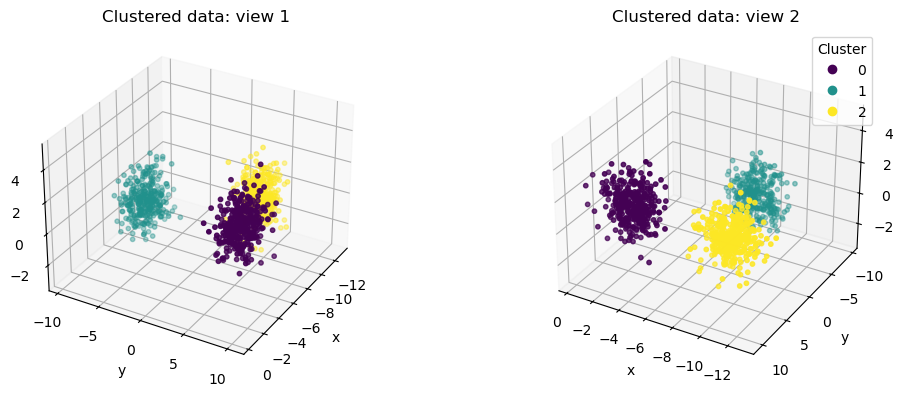

In [13]:
X_blobs, blob_labels = make_blobs(
    n_samples=1000, n_features=3, random_state=2023
)
print('Clustered data matrix:', X_blobs.shape)

fig = plt.figure(figsize=(11, 4.5))
fig.subplots_adjust(left=0.08, right=0.9, bottom=0.13, top=0.9, wspace=0.3)
for position, azimuth in enumerate([30, 120], start=1):
    ax = fig.add_subplot(1, 2, position, projection='3d')
    points = ax.scatter(
        X_blobs[:, 0], X_blobs[:, 1], X_blobs[:, 2],
        c=blob_labels, cmap='viridis', s=10
    )
    ax.set(xlabel='x', ylabel='y', zlabel='z', title=f'Clustered data: view {position}')
    ax.view_init(30, azimuth)
    ax.set_zlabel('z', labelpad=0)
ax.legend(*points.legend_elements(), title='Cluster', loc='upper right')
plt.show()

#### Change only the initialization seed

The two t-SNE fits use the same data, perplexity, learning rate, iteration limit, and Barnes-Hut approximation. Only the initialization seed changes. PCA provides a linear reference on these same data.

In [14]:
blob_settings = dict(
    n_components=2, perplexity=30, method='barnes_hut', angle=0.6,
    init='random', learning_rate='auto', max_iter=1000
)
blob_models = {}
for seed in [2023, 5]:
    start = time.perf_counter()
    model = TSNE(**blob_settings, random_state=seed,
                 verbose=1 if seed == 2023 else 0).fit(X_blobs)
    blob_models[seed] = model
    print(f'Seed {seed}: KL={model.kl_divergence_:.6f}, '
          f'time={time.perf_counter() - start:.2f} seconds')

Z_blobs_pca = PCA(n_components=2, svd_solver='full').fit_transform(X_blobs)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 1000 samples in 0.001s...
[t-SNE] Computed neighbors for 1000 samples in 0.016s...
[t-SNE] Computed conditional probabilities for sample 1000 / 1000
[t-SNE] Mean sigma: 0.587835
[t-SNE] KL divergence after 250 iterations with early exaggeration: 58.306877
[t-SNE] KL divergence after 1000 iterations: 0.695682
Seed 2023: KL=0.695682, time=1.01 seconds
Seed 5: KL=0.664190, time=0.97 seconds


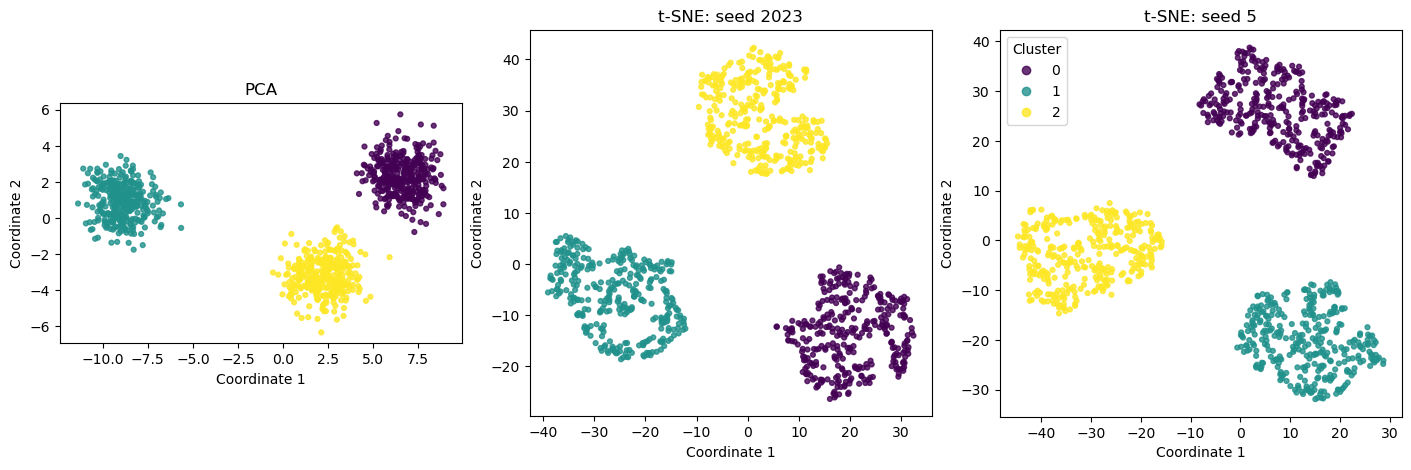

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout='constrained')
embeddings = [Z_blobs_pca] + [model.embedding_ for model in blob_models.values()]
titles = ['PCA'] + [f't-SNE: seed {seed}' for seed in blob_models]
for ax, embedding, title in zip(axes, embeddings, titles):
    points = ax.scatter(embedding[:, 0], embedding[:, 1],
                        c=blob_labels, cmap='viridis', s=12, alpha=0.8)
    ax.set(xlabel='Coordinate 1', ylabel='Coordinate 2', title=title)
    ax.set_aspect('equal', adjustable='box')
axes[-1].legend(*points.legend_elements(), title='Cluster', loc='best')
plt.show()

#### Interpretation questions

- Do both methods reveal the three clusters? Were these data difficult for PCA?
- What changes between the two t-SNE runs, and what remains stable?
- Why do rotations and reflections alone not indicate a change in embedding quality?

Do not read inter-cluster distances or cluster areas in t-SNE as faithful measurements of the original geometry. A lower final KL value compares fits to the same target affinities; it is not a classification accuracy.

### Example 2. A Swiss roll: local neighborhoods and global geometry

Generate 1,000 Swiss-roll points. The color represents the continuous position along the roll, not a class label. Divide all coordinates by one common scalar for numerical scaling; this preserves their relative Euclidean distances. We do not standardize each feature separately.

The MDS/Isomap demo uses digit images instead. Here the Swiss roll provides a data set with known intrinsic geometry: compare the t-SNE plots below with the Isomap unrolling discussed in lecture and explored in HW3. The common scalar rescaling changes distance units, not the underlying geometry.

Swiss-roll data matrix: (1000, 3)


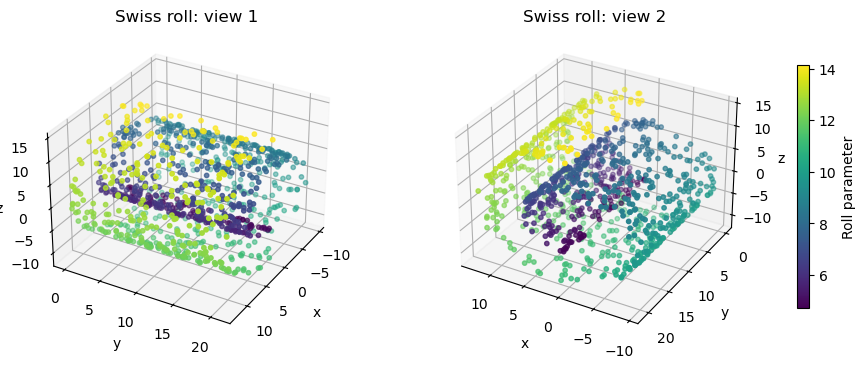

In [16]:
X_roll, roll_parameter = make_swiss_roll(
    n_samples=1000, noise=0.05, random_state=2022
)
X_roll_scaled = X_roll / X_roll.std()
print('Swiss-roll data matrix:', X_roll_scaled.shape)

fig = plt.figure(figsize=(11, 4.5))
fig.subplots_adjust(left=0.08, right=0.9, bottom=0.13, top=0.9, wspace=0.3)
roll_axes = []
for position, azimuth in enumerate([30, 120], start=1):
    ax = fig.add_subplot(1, 2, position, projection='3d')
    roll_axes.append(ax)
    points = ax.scatter(
        X_roll[:, 0], X_roll[:, 1], X_roll[:, 2],
        c=roll_parameter, cmap='viridis', s=10
    )
    ax.set(xlabel='x', ylabel='y', zlabel='z', title=f'Swiss roll: view {position}')
    ax.view_init(30, azimuth)
    ax.set_zlabel('z', labelpad=0)
fig.colorbar(points, ax=roll_axes, shrink=0.7, label='Roll parameter')
plt.show()

#### Exact t-SNE

Use a fixed seed and perplexity 30. The small learning rate below is a deliberate setting for this Swiss-roll example, not the library default. Keep it fixed in the comparisons that follow.

In [17]:
roll_settings = dict(
    n_components=2, method='exact', learning_rate=1,
    init='random', max_iter=1000
)
roll_seed = 2022
start = time.perf_counter()
roll_baseline = TSNE(
    **roll_settings, perplexity=30, random_state=roll_seed
).fit(X_roll_scaled)
print(f'Exact t-SNE: {time.perf_counter() - start:.2f} seconds')
print(f'Final KL: {roll_baseline.kl_divergence_:.6f}')

Exact t-SNE: 11.60 seconds
Final KL: 0.551833


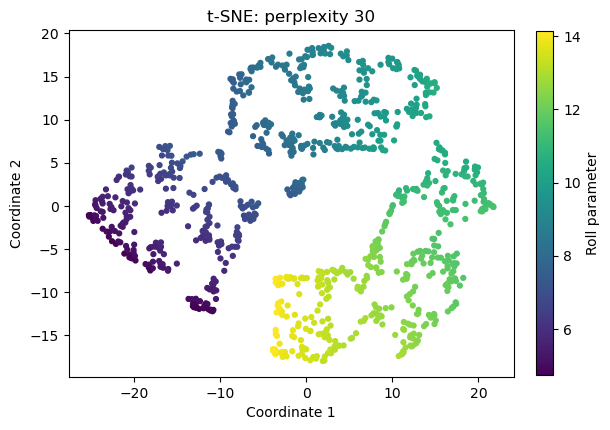

In [18]:
fig, ax = plt.subplots(figsize=(6, 5), layout='constrained')
embedding = roll_baseline.embedding_
points = ax.scatter(embedding[:, 0], embedding[:, 1],
                    c=roll_parameter, cmap='viridis', s=12)
ax.set(xlabel='Coordinate 1', ylabel='Coordinate 2',
       title='t-SNE: perplexity 30')
ax.set_aspect('equal', adjustable='box')
fig.colorbar(points, ax=ax, shrink=0.7, label='Roll parameter')
plt.show()

#### Change only perplexity

Hold the data, initialization seed (2022), exact method, learning rate (1), and iteration limit (1000) fixed. Compare perplexities 10, 30, and 100; reuse the perplexity-30 fit from above.

Before running, predict whether increasing the effective neighborhood size will produce a more local or broader view of the data.

In [19]:
perplexity_models = {30: roll_baseline}
for perplexity in [10, 100]:
    start = time.perf_counter()
    model = TSNE(
        **roll_settings, perplexity=perplexity, random_state=roll_seed
    ).fit(X_roll_scaled)
    perplexity_models[perplexity] = model
    print(f'Perplexity {perplexity}: KL={model.kl_divergence_:.6f}, '
          f'time={time.perf_counter() - start:.2f} seconds')

Perplexity 10: KL=0.722931, time=11.77 seconds
Perplexity 100: KL=0.528398, time=11.85 seconds


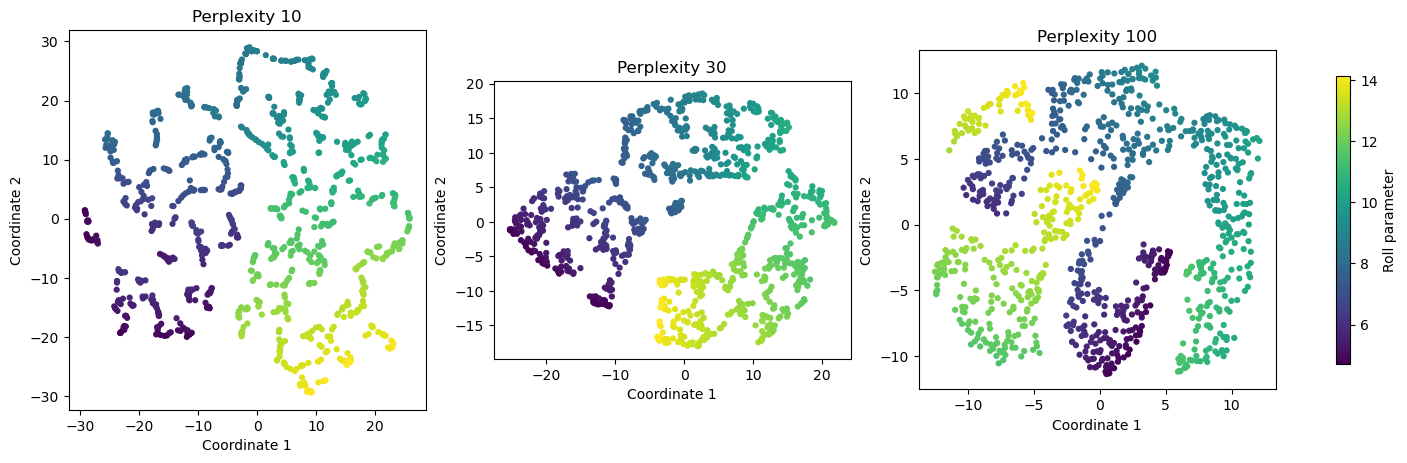

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout='constrained')
for ax, perplexity in zip(axes, [10, 30, 100]):
    embedding = perplexity_models[perplexity].embedding_
    points = ax.scatter(embedding[:, 0], embedding[:, 1],
                        c=roll_parameter, cmap='viridis', s=12)
    ax.set(xlabel='Coordinate 1', ylabel='Coordinate 2',
           title=f'Perplexity {perplexity}')
    ax.set_aspect('equal', adjustable='box')
fig.colorbar(points, ax=axes, shrink=0.7, label='Roll parameter')
plt.show()

#### Interpretation questions

- How does perplexity change the local groups and the overall arrangement?
- Do these plots recover a globally faithful, unrolled strip?
- Why can preserving local neighbors still distort global geometry?
- Why should we avoid selecting a perplexity solely by comparing the displayed KL values?

Changing perplexity changes the input affinities $p_{ij}$, so the objective itself changes. KL values across perplexities are not scores for the same fitting problem.

### Optional. Repeat the Swiss-roll embedding with different seeds

Perplexity remains 100, and every other setting stays fixed. Reuse seed 2022 from the preceding comparison and compute two additional initializations. This extends the seed experiment from Example 1 to non-clustered manifold data.

In [21]:
roll_seed_models = {2022: perplexity_models[100]}
for seed in [202, 2024]:
    start = time.perf_counter()
    model = TSNE(
        **roll_settings, perplexity=100, random_state=seed
    ).fit(X_roll_scaled)
    roll_seed_models[seed] = model
    print(f'Seed {seed}: KL={model.kl_divergence_:.6f}, '
          f'time={time.perf_counter() - start:.2f} seconds')

Seed 202: KL=0.527998, time=12.11 seconds
Seed 2024: KL=0.510970, time=12.07 seconds


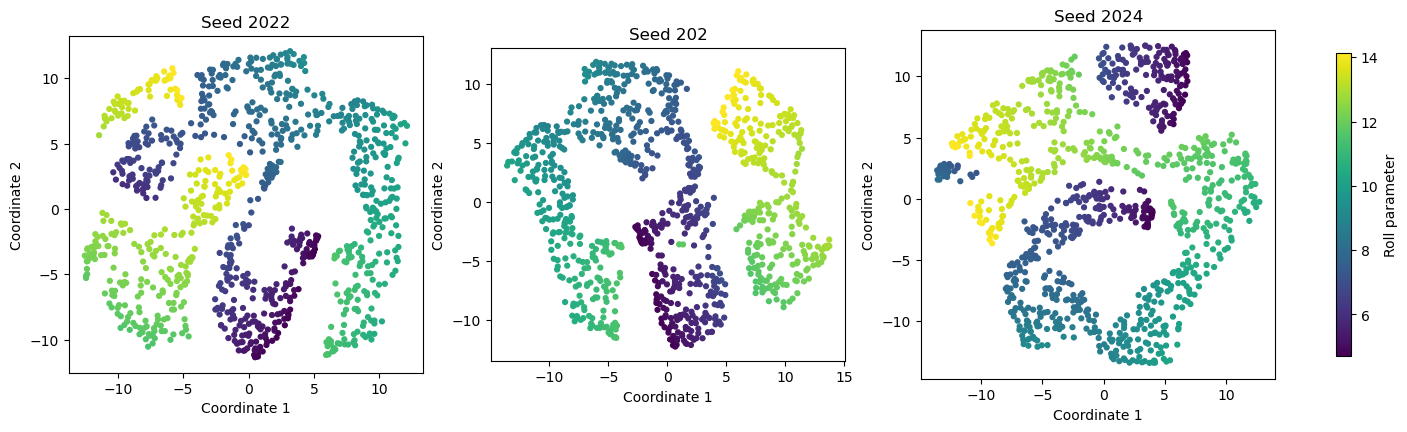

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout='constrained')
for ax, (seed, model) in zip(axes, roll_seed_models.items()):
    embedding = model.embedding_
    points = ax.scatter(embedding[:, 0], embedding[:, 1],
                        c=roll_parameter, cmap='viridis', s=12)
    ax.set(xlabel='Coordinate 1', ylabel='Coordinate 2', title=f'Seed {seed}')
    ax.set_aspect('equal', adjustable='box')
fig.colorbar(points, ax=axes, shrink=0.7, label='Roll parameter')
plt.show()

### Discussion

- The clustered example is easy for both PCA and t-SNE; t-SNE does not automatically improve every data set.
- On the Swiss roll, the tested t-SNE embeddings emphasize local neighborhoods without recovering a globally faithful unrolling.
- The t-SNE objective is nonconvex. Inspect multiple initializations and neighborhood scales before interpreting the layout.